# Robust Regression: NLP Sentiment Change vs Memory
Testing the association between the change in positive/negative sentiment ratio from pre- to post-task, and the Day 2 memory success (Win and Lose).
Predictor (X): `(pre_pos / (pre_neg + 0.001)) - (post_pos / (post_neg + 0.001))`


In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import pandas as pd
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')


In [2]:
# Load Data
df_mem = pd.read_csv('../data/allsubs_combined.csv')
sub_mem = df_mem.groupby('Sub').first().reset_index()

df_nlp = pd.read_csv('../data/free_recall_nlp.csv')

# Merge
df_merged = pd.merge(sub_mem, df_nlp, on='Sub', how='inner')

# Drop missing values
df_merged = df_merged.dropna(subset=['day_1_pre_pos', 'day_1_pre_neg', 'day_1_post_pos', 'day_1_post_neg', 'Day2_Win_Success', 'Day2_Lose_Success'])

# Calculate ratio change
# Using + 0.001 to prevent division by zero for subjects with 0 negative sentiment
df_merged['pre_ratio'] = df_merged['day_1_pre_pos'] / (df_merged['day_1_pre_neg'] + 0.001)
df_merged['post_ratio'] = df_merged['day_1_post_pos'] / (df_merged['day_1_post_neg'] + 0.001)
df_merged['nlp_change'] = df_merged['pre_ratio'] - df_merged['post_ratio']

y_win = df_merged['Day2_Win_Success'].values
y_lose = df_merged['Day2_Lose_Success'].values

# Z-transform the NLP change for the predictor
x_raw = stats.zscore(df_merged['nlp_change'].values)
x = x_raw

print(f"Running regression on {len(x)} subjects.")


Running regression on 64 subjects.


In [3]:
def run_robust_regression(x, y, name):
    with pm.Model() as RR:
        a = pm.Normal('intercept', mu=np.mean(y), sigma=0.5)
        b = pm.Normal('slope', mu=0, sigma=0.5)
        eps = pm.TruncatedNormal('eps', mu=np.std(y), sigma=0.5, lower=0.05)
        
        y_hat = a + b * x
        nu_raw = pm.Gamma("nu_raw", alpha=2, beta=0.1)
        nu = pm.Deterministic("nu", nu_raw + 2.0)
        
        likelihood = pm.StudentT("likelihood", mu=y_hat, sigma=eps, nu=nu, observed=y)
        
        trace_robust = pm.sample(nuts_sampler="numpyro", draws=2000, tune=2000, chains=4, progressbar=False)
        
    return trace_robust, RR

print("Running Robust Regression for Win Memory...")
trace_win, model_win = run_robust_regression(x, y_win, "Win")

print("Running Robust Regression for Lose Memory...")
trace_lose, model_lose = run_robust_regression(x, y_lose, "Lose")

# Standard Pearson Regression
r_win, p_win = stats.pearsonr(x_raw, y_win)
r_lose, p_lose = stats.pearsonr(x_raw, y_lose)


Running Robust Regression for Win Memory...


Running Robust Regression for Lose Memory...


STANDARD PEARSON CORRELATION
NLP Change -> Win Memory:  r = 0.064, p = 0.6135
NLP Change -> Lose Memory: r = 0.044, p = 0.7324

ROBUST REGRESSION RESULTS (89% HDI)
NLP Change -> Win Memory HDI 89%: [-0.047, 0.060] -> INCLUDES 0
NLP Change -> Lose Memory HDI 89%: [-0.044, 0.062] -> INCLUDES 0



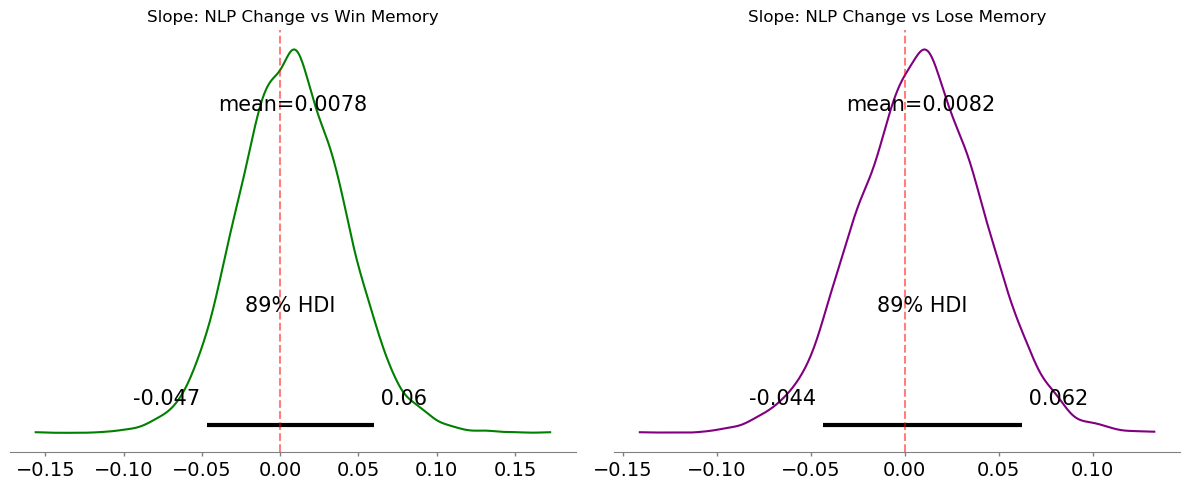

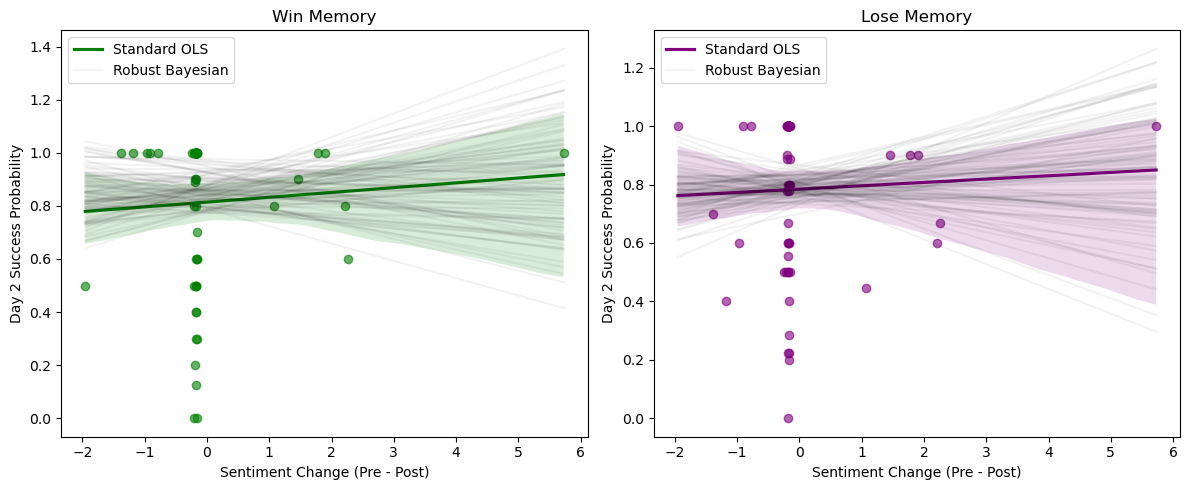

In [4]:
# Extract slopes
slope_win_samples = trace_win.posterior['slope'].values.flatten()
slope_lose_samples = trace_lose.posterior['slope'].values.flatten()

# Calculate 89% HDI
hdi_win = az.hdi(slope_win_samples, hdi_prob=0.89)
hdi_lose = az.hdi(slope_lose_samples, hdi_prob=0.89)

def check_significance(hdi, slope_name):
    includes_zero = hdi[0] <= 0 <= hdi[1]
    status = "INCLUDES 0" if includes_zero else "EXCLUDES 0"
    print(f"{slope_name} HDI 89%: [{hdi[0]:.3f}, {hdi[1]:.3f}] -> {status}")

print("==================================================")
print("STANDARD PEARSON CORRELATION")
print("==================================================")
print(f"NLP Change -> Win Memory:  r = {r_win:.3f}, p = {p_win:.4f}")
print(f"NLP Change -> Lose Memory: r = {r_lose:.3f}, p = {p_lose:.4f}")
print("\n==================================================")
print("ROBUST REGRESSION RESULTS (89% HDI)")
print("==================================================")
check_significance(hdi_win, "NLP Change -> Win Memory")
check_significance(hdi_lose, "NLP Change -> Lose Memory")
print("==================================================\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

az.plot_posterior(trace_win.posterior, var_names=['slope'], hdi_prob=0.89, ax=axes[0], color="green")
axes[0].set_title("Slope: NLP Change vs Win Memory")
axes[0].axvline(0, color='red', linestyle='--', alpha=0.5)

az.plot_posterior(trace_lose.posterior, var_names=['slope'], hdi_prob=0.89, ax=axes[1], color="purple")
axes[1].set_title("Slope: NLP Change vs Lose Memory")
axes[1].axvline(0, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Plot the regression lines
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, (y, trace, title, color) in enumerate(zip([y_win, y_lose], [trace_win, trace_lose], ["Win Memory", "Lose Memory"], ["green", "purple"])):
    ax = axes[i]
    
    # Plot standard OLS trend line
    sns.regplot(x=x_raw, y=y, ax=ax, color=color, scatter_kws={'alpha': 0.6}, line_kws={'label': 'Standard OLS'})
    
    # Plot 100 posterior draws from the Robust Regression
    a_samples = trace.posterior['intercept'].values.flatten()
    b_samples = trace.posterior['slope'].values.flatten()
    
    idx = np.random.choice(len(a_samples), 100, replace=False)
    
    x_range_raw = np.linspace(min(x_raw), max(x_raw), 100)
    x_range_std = (x_range_raw - np.mean(x_raw)) / np.std(x_raw)
    
    for a, b in zip(a_samples[idx], b_samples[idx]):
        y_hat = a + b * x_range_std
        label = 'Robust Bayesian' if a == a_samples[idx][0] else None
        ax.plot(x_range_raw, y_hat, color='black', alpha=0.05, label=label)
        
    ax.set_title(title)
    ax.set_xlabel("Sentiment Change (Pre - Post)")
    ax.set_ylabel("Day 2 Success Probability")
    
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys())

plt.tight_layout()
plt.show()
